GOAL IS TO CHECK IF THE PERSON WILL DEFAULT ON LOAN. 0 - 1.

In [1]:
from sklearn._config import set_config
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, train_test_split
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder

Accuracy Score: 86.67
Recall Score: 66.67
Classification report:               precision    recall  f1-score   support

     Default       0.96      0.89      0.92        27
        Safe       0.40      0.67      0.50         3

    accuracy                           0.87        30
   macro avg       0.68      0.78      0.71        30
weighted avg       0.90      0.87      0.88        30



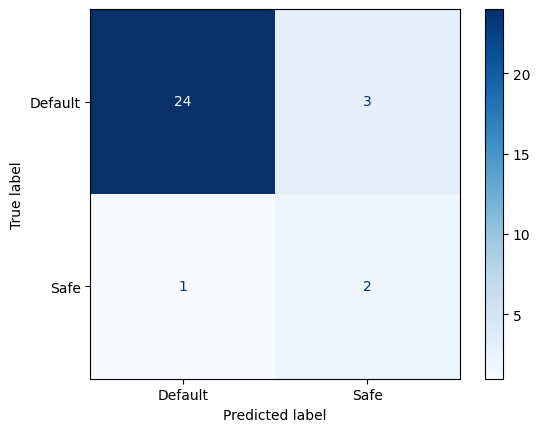

In [2]:
set_config(transform_output='pandas')
df = pd.read_csv("credit_loan.csv")

X = df.drop(columns='default')
y = df['default']

# create training split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)
# what does strasify do?

#preprocess data
categorical_features = X.select_dtypes(include=['str', 'category']).columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
preprocess_data = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), numeric_features),
        ('encoder', OneHotEncoder(sparse_output=False), categorical_features)
    ]
)

# create Pipeline
pipe = Pipeline([
    ('prep', preprocess_data),
    ('model', LogisticRegression(class_weight='balanced'))
])

# create gridseach cv
model = GridSearchCV(
    estimator=pipe,
    param_grid={
        'model__random_state': [42]
    },
    scoring=['precision', 'recall', 'f1'],
    refit='precision',
    cv=5
)

# train data
model.fit(X_train, y_train)

# model prediction
model_prediction = model.predict(X_test)

# print accuracy score
accuracy = accuracy_score(y_test, model_prediction)
print(f"Accuracy Score: {accuracy * 100:.2f}")

# print accuracy score
recall = recall_score(y_test, model_prediction)
print(f"Recall Score: {recall * 100:.2f}")


# print accuracy score
classification = classification_report(y_test, model_prediction, target_names=['Default', 'Safe'])
print(f"Classification report: {classification}")

# confusion matrix
cm = confusion_matrix(y_test, model_prediction)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Default', 'Safe'])

disp.plot(cmap='Blues')
plt.show()

RANDOM FOREST CLASSIFIER

C:\Users\hp\AppData\Roaming\Python\Python314\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Accuracy Score: 90.00
Recall Score: 66.67
Classification report:               precision    recall  f1-score   support

     Default       0.96      0.93      0.94        27
        Safe       0.50      0.67      0.57         3

    accuracy                           0.90        30
   macro avg       0.73      0.80      0.76        30
weighted avg       0.92      0.90      0.91        30



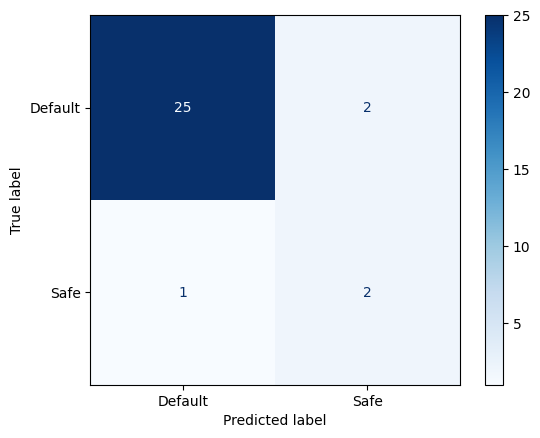

                                     Feature  Importance
8                          remainder__income    0.292430
10                   remainder__credit_score    0.174361
11              remainder__previous_defaults    0.128662
7                             remainder__age    0.102625
12           remainder__debt_to_income_ratio    0.080124
2      encoder__employment_status_unemployed    0.056129
9                     remainder__loan_amount    0.050779
5                 encoder__loan_purpose_home    0.028686
1   encoder__employment_status_self-employed    0.027177
4                  encoder__loan_purpose_car    0.023046
0        encoder__employment_status_employed    0.017137
6             encoder__loan_purpose_personal    0.013062
3             encoder__loan_purpose_business    0.005783


In [3]:
set_config(transform_output='pandas')
df = pd.read_csv("credit_loan.csv")

X = df.drop(columns='default')
y = df['default']

# create training split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# what does strasify do?

#preprocess data
categorical_features = X.select_dtypes(include=['str', 'category']).columns

preprocess_data = ColumnTransformer(
    transformers=[
        ('encoder', OneHotEncoder(sparse_output=False), categorical_features)
    ],
    remainder='passthrough'
)

# create Pipeline
pipe = Pipeline([
    ('prep', preprocess_data),
    ('model', RandomForestClassifier(random_state=42, class_weight='balanced')),
])

# create gridseach cv
model = GridSearchCV(
    estimator=pipe,
    param_grid={
        'model__n_estimators': [5],
        'model__max_depth': [5],
    },
    scoring=['precision', 'recall', 'f1'],
    refit='precision',
    cv=5,
)
# train data
model.fit(X_train, y_train)

# model prediction
model_prediction = model.predict(X_test)

# print accuracy score
accuracy = accuracy_score(y_test, model_prediction)
print(f"Accuracy Score: {accuracy * 100:.2f}")

# print accuracy score
recall = recall_score(y_test, model_prediction)
print(f"Recall Score: {recall * 100:.2f}")

# print accuracy score
classification = classification_report(y_test, model_prediction, target_names=['Default', 'Safe'])
print(f"Classification report: {classification}")

# confusion matrix
cm = confusion_matrix(y_test, model_prediction)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Default', 'Safe'])

disp.plot(cmap='Blues')
plt.show()

# 1. Grab the winning FITTED pipeline
best_pipe = model.best_estimator_

# 2. Get names from the FITTED preprocessor
feature_names = best_pipe.named_steps['prep'].get_feature_names_out()

# 3. Get importances from the FITTED model (Random Forest)
importances = best_pipe.named_steps['model'].feature_importances_

# 4. Combine into a DataFrame and print
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Sort so the "MVP" features are at the top
print(importance_df.sort_values(by='Importance', ascending=False))
